# 01 – Return và volatility (GĐ 1, Buổi 1)

Danh mục mặc định: NVDA, AAPL, TSLA, MSFT, JPM, KO, PEP + SPY (benchmark).
Đọc batch raw mới nhất từ `$RISKLAB_DATA/raw/yfinance/prices_daily/`. Return tính từ **`adj_close`** (đã điều chỉnh chia tách và cổ tức).

Mở JupyterLab bằng `uv run jupyter lab` **từ shell đã `source session.sh`**, nếu không kernel sẽ không thấy `RISKLAB_DATA`.

In [1]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TICKERS = ["NVDA", "AAPL", "TSLA", "MSFT", "JPM", "KO", "PEP", "SPY"]
STOCKS = TICKERS[:-1]          # 7 cổ phiếu; SPY là benchmark, không nằm trong danh mục
TRADING_DAYS = 252

data_root = os.environ["RISKLAB_DATA"]
assert data_root.startswith("/Volumes/RiskLab/"), data_root
RAW = Path(data_root) / "raw" / "yfinance" / "prices_daily"
latest = sorted(p for p in RAW.glob("batch_id=*") if p.is_dir())[-1]
manifest = json.loads((latest / "manifest.json").read_text())
print(latest.name, "| yfinance", manifest["yfinance_version"], "| auto_adjust =", manifest["auto_adjust"])

px_long = pd.read_parquet(latest / "prices.parquet")
px_long["trade_date"] = pd.to_datetime(px_long["trade_date"])

def wide(col):
    return px_long.pivot(index="trade_date", columns="ticker", values=col).sort_index()[TICKERS]

px = wide("adj_close")      # giá đã điều chỉnh chia tách + cổ tức -> dùng cho return
close = wide("close")       # Close của Yahoo: đã điều chỉnh chia tách, CHƯA điều chỉnh cổ tức
print(px.shape, px.index.min().date(), "->", px.index.max().date())
print("NaN mỗi mã:", px.isna().sum().to_dict())

Matplotlib is building the font cache; this may take a moment.


batch_id=20261108T103206Z | yfinance 1.8.0 | auto_adjust = False
(2980, 8) 2015-01-02 -> 2026-11-06
NaN mỗi mã: {'NVDA': 0, 'AAPL': 0, 'TSLA': 0, 'MSFT': 0, 'JPM': 0, 'KO': 0, 'PEP': 0, 'SPY': 0}


## 1. Simple return và log return

$r^{simple}_t = P_t/P_{t-1} - 1$  ·  $r^{log}_t = \ln(P_t/P_{t-1}) = \ln(1 + r^{simple}_t)$

In [2]:
r_simple = (px / px.shift(1) - 1).iloc[1:]
r_log = np.log(px / px.shift(1)).iloc[1:]
print("Số phiên có return:", len(r_simple))
r_simple.tail(3).round(4)

Số phiên có return: 2979


ticker,NVDA,AAPL,TSLA,MSFT,JPM,KO,PEP,SPY
trade_date,,,,,,,,
2026-11-04,-0.0317,0.0531,-0.0334,0.0668,0.0418,0.0105,0.0375,0.0165
2026-11-05,-0.0926,-0.0153,-0.1077,-0.0358,-0.0419,-0.0007,0.0020,-0.0441
2026-11-06,0.0278,-0.0052,0.0423,-0.0099,-0.0084,-0.0006,-0.0096,0.0031


### 1a. Cộng theo **thời gian**: log return cộng được, simple return thì không

In [3]:
s = "SPY"
total_true = px[s].iloc[-1] / px[s].iloc[0] - 1
print(f"{s} tổng return thật           : {total_true:9.4%}")
print(f"{s} cộng dồn simple return     : {r_simple[s].sum():9.4%}   <- sai")
print(f"{s} exp(cộng log return) - 1   : {np.expm1(r_log[s].sum()):9.4%}   <- khớp")
print(f"{s} tích (1 + simple) - 1      : {(1 + r_simple[s]).prod() - 1:9.4%}   <- khớp")

SPY tổng return thật           : 334.3953%
SPY cộng dồn simple return     : 165.1368%   <- sai
SPY exp(cộng log return) - 1   : 334.3953%   <- khớp
SPY tích (1 + simple) - 1      : 334.3953%   <- khớp


### 1b. Cộng theo **tài sản** (trong danh mục): simple return cộng được, log return thì không

Danh mục 7 mã trọng số bằng nhau, cân bằng lại mỗi ngày (giả định đơn giản cho bài này).

In [4]:
w = pd.Series(1 / len(STOCKS), index=STOCKS)
rp_simple = r_simple[STOCKS] @ w            # đúng: return danh mục = tổng có trọng số của simple return
rp_log_true = np.log1p(rp_simple)           # log return thật của danh mục
rp_log_wrong = r_log[STOCKS] @ w            # sai: lấy trung bình log return từng mã
gap = rp_log_wrong - rp_log_true

print("Chênh lệch |sai - thật| (điểm %):")
print((gap.abs() * 100).describe().round(4))
d = gap.abs().idxmax()
print(f"\nNgày lệch nhiều nhất: {d.date()}  thật={rp_log_true[d]:.4%}  sai={rp_log_wrong[d]:.4%}")
print("Dấu của chênh lệch luôn <= 0?", bool((gap <= 1e-15).all()))

Chênh lệch |sai - thật| (điểm %):
count    2979.0000
mean        0.0144
std         0.0240
min         0.0001
25%         0.0036
50%         0.0075
75%         0.0161
max         0.4269
dtype: float64

Ngày lệch nhiều nhất: 2016-11-11  thật=4.5917%  sai=4.1649%
Dấu của chênh lệch luôn <= 0? True


## 2. Volatility và annualization

$\sigma_{năm} = \sigma_{ngày}\sqrt{252}$ (giả định return độc lập, cùng phân phối) · mean năm $\approx \mu_{ngày} \times 252$ · CAGR $= (P_{cuối}/P_{đầu})^{252/N} - 1$

In [5]:
n = len(r_simple)
summary = pd.DataFrame({
    "vol_ngay_%": r_simple.std() * 100,
    "vol_nam_%": r_simple.std() * np.sqrt(TRADING_DAYS) * 100,
    "mean_nam_%": r_simple.mean() * TRADING_DAYS * 100,
    "cagr_%": ((px.iloc[-1] / px.iloc[0]) ** (TRADING_DAYS / n) - 1) * 100,
    "ngay_te_nhat_%": r_simple.min() * 100,
    "ngay_te_nhat": r_simple.idxmin().dt.date,
})
summary.round(2)

,vol_ngay_%,vol_nam_%,mean_nam_%,cagr_%,ngay_te_nhat_%,ngay_te_nhat
ticker,,,,,,
NVDA,3.03,48.06,61.90,65.55,-18.76,2018-11-16
AAPL,1.81,28.66,26.54,25.14,-12.86,2020-03-16
TSLA,3.59,57.02,43.26,31.07,-21.06,2020-09-08
MSFT,1.74,27.61,25.76,24.55,-14.74,2020-03-16
JPM,1.69,26.85,20.41,18.31,-14.96,2020-03-16
KO,1.13,17.91,11.65,10.55,-9.67,2020-03-12
PEP,1.22,19.30,8.32,6.67,-11.43,2020-03-20
SPY,1.10,17.54,13.97,13.23,-10.94,2020-03-16


### 2a. Cổ tức: `close` và `adj_close` khác nhau bao nhiêu mỗi năm?

In [6]:
cagr_adj = (px.iloc[-1] / px.iloc[0]) ** (TRADING_DAYS / n) - 1
cagr_close = (close.iloc[-1] / close.iloc[0]) ** (TRADING_DAYS / n) - 1
pd.DataFrame({"cagr_adj_%": cagr_adj * 100, "cagr_close_%": cagr_close * 100,
              "chenh_%/nam": (cagr_adj - cagr_close) * 100}).round(2)

,cagr_adj_%,cagr_close_%,chenh_%/nam
ticker,,,
NVDA,65.55,64.94,0.61
AAPL,25.14,23.84,1.29
TSLA,31.07,31.07,0.00
MSFT,24.55,22.81,1.74
JPM,18.31,15.25,3.06
KO,10.55,7.18,3.37
PEP,6.67,3.47,3.20
SPY,13.23,11.39,1.84


### 2b. Volatility không cố định: rolling 63 phiên (~1 quý), đã annualize

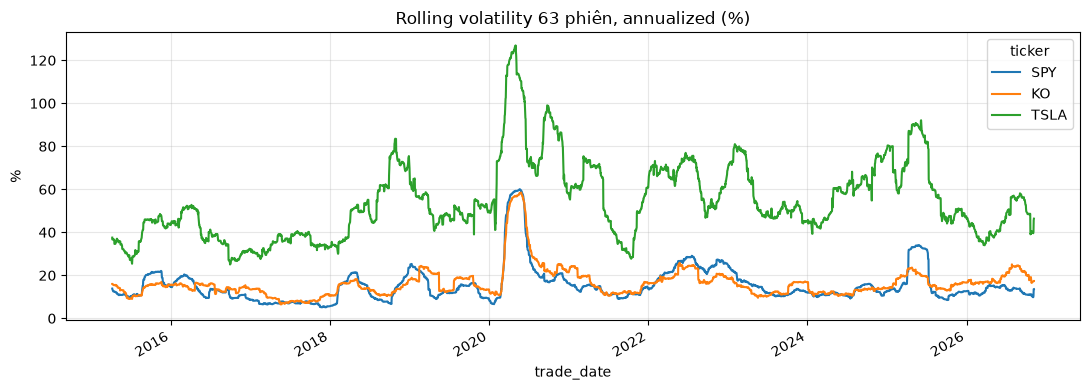

SPY rolling vol: min 5.1%, max 60.0% (ngày 2020-05-20)


In [7]:
roll = r_simple[["SPY", "KO", "TSLA"]].rolling(63).std() * np.sqrt(TRADING_DAYS) * 100
ax = roll.plot(figsize=(11, 4), title="Rolling volatility 63 phiên, annualized (%)")
ax.set_ylabel("%"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("SPY rolling vol: min %.1f%%, max %.1f%% (ngày %s)" %
      (roll["SPY"].min(), roll["SPY"].max(), roll["SPY"].idxmax().date()))

## Ghi chú
- Kết quả này chưa phải VaR. Covariance, correlation, drawdown làm ở buổi sau.
- Dự án học tập, không phải khuyến nghị đầu tư.